### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# Fig 3F · Ureagenesis assay in SLC38A4-KO cells

Urea secretion (mM) into the culture medium following an ammonium chloride (NH4Cl) challenge, in WT vs
two SLC38A4-knockout clones (KO 1 = C12, KO 2 = P1.7). Data: `Fig3F_ureagenesis_assay_data.csv`.

**Statistics**: unpaired Welch's t-test, WT vs each KO, one-tailed (H1: WT > KO), tested on the linear
scale (absolute mM, not a ratio). Directionality is pre-specified by the urea-cycle/nitrogen-metabolism
pathway enrichment and gene-expression results (Fig 3D-E) -- reduced transcription of urea-cycle enzymes
predicts reduced urea output, tested here directly.

This panel was split out of a combined notebook that used to report CYP3A4 activity and urea secretion
together as "Fig 3G"; the two are now reported as separate figure panels (Fig 3F here; CYP3A4 activity is
Fig 3J), matching how they're cited individually in the manuscript text. House style; run with Helvetica
for the final PDF.


In [2]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
AXTITLE=10
plt.rcParams.update({'font.family':'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':10,'axes.linewidth':1.0,'axes.spines.top':False,'axes.spines.right':False,
    'xtick.major.width':1.0,'ytick.major.width':1.0,'xtick.major.size':4,'ytick.major.size':4,
    'pdf.fonttype':42,'ps.fonttype':42,
    'axes.unicode_minus':False})
COLORS={'WT':'#AAAAAA','KO 1':'#D73027','KO 2':'#FC8D59'}   # KO 1 = C12, KO 2 = P1.7
ORDER=['WT','KO 1','KO 2']
def sem(x): return np.std(x,ddof=1)/np.sqrt(len(x)) if len(x)>1 else 0.0
def welch_test(a,b,scale='linear',alternative='two-sided'):
    a=np.asarray(a,float); b=np.asarray(b,float)
    if scale=='log2':
        if (a<=0).any() or (b<=0).any(): return np.nan
        a,b=np.log2(a),np.log2(b)
    return stats.ttest_ind(a,b,equal_var=False,alternative=alternative).pvalue
def fmt_p(p): return 'undetected' if not np.isfinite(p) else (f'p={p:.1e}' if p<1e-4 else f'p={p:.3f}')
def sig_bracket(ax,x1,x2,y,h,text,fontsize=7):
    ax.plot([x1,x1,x2,x2],[y,y+h,y+h,y],color='black',lw=0.8,clip_on=False,zorder=5)
    ax.text((x1+x2)/2,y+h,text,ha='center',va='bottom',fontsize=fontsize,rotation=0)

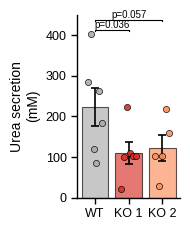

Saved: Fig3F_ureagenesis_assay.pdf


In [3]:
df=pd.read_csv('Fig3F_ureagenesis_assay_data.csv')
ylab='Urea secretion\n(mM)'

SPACING=0.75; WIDTH=0.6; XPAD=0.4
positions=[i*SPACING for i in range(3)]

fig,ax=plt.subplots(figsize=(2,2.4))
wt=df[df.group=='WT']['value'].values
tops=[]
for x,grp in zip(positions,ORDER):
    v=df[df.group==grp]['value'].values
    ax.bar(x,v.mean(),width=WIDTH,color=COLORS[grp],alpha=0.65,edgecolor='black',linewidth=0.8,zorder=2)
    ax.errorbar(x,v.mean(),yerr=sem(v),color='black',lw=1.2,capsize=3,capthick=1.2,ls='none',zorder=3)
    ax.scatter(x+np.linspace(-0.16,0.16,len(v)),v,color=COLORS[grp],edgecolors='black',
               linewidth=0.5,s=20,zorder=4,alpha=0.9); tops.append(v.max())
top=max(tops)
YMAX=450
headroom=YMAX-top
tick_h=headroom*0.08
y_levels=[top+headroom*0.15, top+headroom*0.65]
for (x,grp),y in zip(zip(positions[1:],['KO 1','KO 2']), y_levels):
    kv=df[df.group==grp]['value'].values
    p=welch_test(wt,kv,'linear','greater')
    sig_bracket(ax,positions[0],x,y,tick_h,fmt_p(p))
ax.set_xticks(positions); ax.set_xticklabels(ORDER,rotation=0)
ax.tick_params(axis='both', labelsize=9)
ax.set_ylabel(ylab,fontsize=AXTITLE)
ax.set_xlim(positions[0]-XPAD, positions[-1]+XPAD)
ax.set_ylim(0,YMAX)
plt.tight_layout()
fig.savefig('Fig3F_ureagenesis_assay.pdf',bbox_inches='tight',pad_inches=0.28); plt.show()
print('Saved: Fig3F_ureagenesis_assay.pdf')

# Hepatocyte-function markers in SLC38A4-KO cells by RNA-seq


In [4]:
rnaseq_ko1 = pd.read_csv('FigS7_limma_KO1_vs_WT_mincount10.csv')
rnaseq_ko2 = pd.read_csv('FigS7_limma_KO2_vs_WT_mincount10.csv')

def rnaseq_lookup(rdf, gene):
    hit = rdf[rdf.gene_symbol == gene]
    if len(hit):
        r = hit.iloc[0]
        return round(r['logFC'], 3), r['adj.P.Val']
    return np.nan, np.nan   # gene not present in the tested/filtered RNA-seq gene set

GENES=['CYP3A4','CYP7A1','ABCB11','ABCC2']
detect_rows=[]
for g in GENES:
    fc1,fdr1 = rnaseq_lookup(rnaseq_ko1, g)
    fc2,fdr2 = rnaseq_lookup(rnaseq_ko2, g)
    detect_rows.append({'gene':g,'detected_in_RNAseq': np.isfinite(fc1) or np.isfinite(fc2),
                         'KO1_logFC':fc1,'KO1_adj.P.Val':fdr1,'KO2_logFC':fc2,'KO2_adj.P.Val':fdr2})
rnaseq_detect = pd.DataFrame(detect_rows)
display(rnaseq_detect)

missing = rnaseq_detect.loc[~rnaseq_detect.detected_in_RNAseq,'gene'].tolist()
print(f"Not present in the RNA-seq DE table (filtered pre-testing, likely low/undetectable counts): {missing}")
print("-> qPCR (below) is needed to directly test these genes, since RNA-seq alone can't assess them.")

,gene,detected_in_RNAseq,KO1_logFC,KO1_adj.P.Val,KO2_logFC,KO2_adj.P.Val
0,CYP3A4,False,NaN,NaN,NaN,NaN
1,CYP7A1,False,NaN,NaN,NaN,NaN
2,ABCB11,True,-4.019,1.341627e-08,-4.392,9.612468e-09
3,ABCC2,True,-1.042,1.753741e-15,-0.361,1.951423e-08


Not present in the RNA-seq DE table (filtered pre-testing, likely low/undetectable counts): ['CYP3A4', 'CYP7A1']
-> qPCR (below) is needed to directly test these genes, since RNA-seq alone can't assess them.


# RT-qPCR of hepatocyte-function markers in SLC38A4-KO cells

Relative mRNA expression (normalised to WT = 1) of the drug-metabolism enzyme CYP3A4 and the
bile-acid pathway (CYP7A1, ABCB11/BSEP, ABCC2/MRP2) in WT vs two SLC38A4-knockout clones (KO 1 = C12, KO 2 = P1.7). Data: `Fig3I_hepatocyte_function_qPCR_data.csv`.
Statistics: unpaired Welch's t-test on log2 relative expression (WT vs each KO); undetectable
(0) values preclude a log2 test (n/a). House style; run with Helvetica for the final PDF.


In [5]:
df=pd.read_csv('Fig3I_CYP_ABC_expression_data.csv')
GENES=['CYP3A4','CYP7A1','ABCB11','ABCC2']   # bile-acid-pathway genes listed by gene symbol (ABCB11=BSEP, ABCC2=MRP2)
rows=[]
for g in GENES:
    wt=df[(df.gene==g)&(df.group=='WT')]['rel_expression'].values
    for ko in ['KO 1','KO 2']:
        kv=df[(df.gene==g)&(df.group==ko)]['rel_expression'].values
        rows.append({'gene':g,'comp':f'WT vs {ko}','n_WT':len(wt),'n_KO':len(kv),
                     'mean_KO':round(kv.mean(),3) if len(kv) else np.nan,'p':welch_test(wt,kv,'log2','two-sided')})
pv=pd.DataFrame(rows); display(pv.assign(p=pv.p.map(fmt_p)))
P={(r.gene,r.comp):r.p for _,r in pv.iterrows()}

,gene,comp,n_WT,n_KO,mean_KO,p
0,CYP3A4,WT vs KO 1,6,6,0.322,p=2.5e-06
1,CYP3A4,WT vs KO 2,6,6,0.350,p=2.2e-05
2,CYP7A1,WT vs KO 1,3,3,0.000,undetected
3,CYP7A1,WT vs KO 2,3,3,0.510,p=0.444
4,ABCB11,WT vs KO 1,6,5,0.022,p=9.1e-07
5,ABCB11,WT vs KO 2,6,6,0.018,p=5.4e-10
6,ABCC2,WT vs KO 1,3,3,0.390,p=0.018
7,ABCC2,WT vs KO 2,3,3,0.720,p=0.181


In [6]:
# ============================================================
# Orthogonal validation: for the two genes RNA-seq could test
# (ABCB11, ABCC2), compare qPCR fold-change vs RNA-seq
# ============================================================
rows=[]
for g in ['ABCB11','ABCC2']:
    wt_mean = df[(df.gene==g)&(df.group=='WT')]['rel_expression'].mean()
    for ko_label, rdf in [('KO 1', rnaseq_ko1), ('KO 2', rnaseq_ko2)]:
        ko_mean = df[(df.gene==g)&(df.group==ko_label)]['rel_expression'].mean()
        qpcr_log2fc = np.log2(ko_mean/wt_mean) if ko_mean>0 else np.nan
        rna_logfc, rna_fdr = rnaseq_lookup(rdf, g)
        rows.append({'gene':g,'KO':ko_label,'qPCR log2FC':round(qpcr_log2fc,2),
                     'RNA-seq logFC':rna_logfc,'RNA-seq adj.P.Val':rna_fdr})
display(pd.DataFrame(rows))

,gene,KO,qPCR log2FC,RNA-seq logFC,RNA-seq adj.P.Val
0,ABCB11,KO 1,-5.51,-4.019,1.341627e-08
1,ABCB11,KO 2,-5.77,-4.392,9.612468e-09
2,ABCC2,KO 1,-1.36,-1.042,1.753741e-15
3,ABCC2,KO 2,-0.47,-0.361,1.951423e-08


## Fig 3I

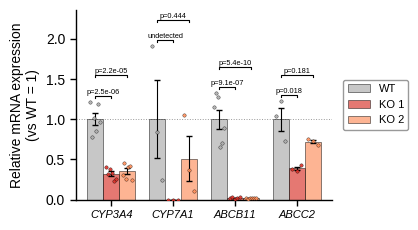

Saved: Fig3I_CYP_ABC_expression.pdf


In [7]:
x=np.arange(len(GENES)); w=0.26; off={'WT':-w,'KO 1':0.0,'KO 2':w}
fig,ax=plt.subplots(figsize=(4.3,2.4))   # widened from 3.4->4.3 so gene names sit horizontal; height unchanged (matches panels F/I)

local_top={}
for gene in GENES:
    local_top[gene]=df[df.gene==gene]['rel_expression'].max()
GLOBAL_TOP=max(local_top.values())
YMAX=GLOBAL_TOP+0.45
TICK_H=0.025

for g_i,grp in enumerate(ORDER):
    for xi,gene in enumerate(GENES):
        v=df[(df.gene==gene)&(df.group==grp)]['rel_expression'].values
        if not len(v): continue
        xc=xi+off[grp]
        ax.bar(xc,v.mean(),width=w,color=COLORS[grp],alpha=0.65,edgecolor='black',linewidth=0.5,
               zorder=2,label=grp if xi==0 else None)
        ax.errorbar(xc,v.mean(),yerr=sem(v),color='black',lw=0.8,capsize=2,ls='none',zorder=3)
        ax.scatter(xc+np.linspace(-w*0.3,w*0.3,len(v)),v,color=COLORS[grp],edgecolors='black',
                   linewidth=0.25,s=6,zorder=4,alpha=0.9)

for xi,gene in enumerate(GENES):
    lt=local_top[gene]
    y1=lt+0.05; y2=lt+0.30
    p1=P.get((gene,'WT vs KO 1'),np.nan)
    p2=P.get((gene,'WT vs KO 2'),np.nan)
    sig_bracket(ax,xi-w,xi,y1,TICK_H,fmt_p(p1),fontsize=5.3)
    sig_bracket(ax,xi-w,xi+w,y2,TICK_H,fmt_p(p2),fontsize=5.3)

ax.axhline(1.0,color='0.6',lw=0.7,ls=':',zorder=1)
ax.set_xticks(x); ax.set_xticklabels(GENES,fontsize=8,fontstyle='italic',rotation=0,ha='center')
ax.set_ylabel('Relative mRNA expression\n(vs WT = 1)',fontsize=AXTITLE)
ax.set_ylim(0,YMAX)
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02,0.5),
          frameon=True, framealpha=0.8, edgecolor='grey')
plt.tight_layout()
fig.savefig('Fig3I_CYP_ABC_expression.pdf',bbox_inches='tight'); plt.show()
print('Saved: Fig3I_CYP_ABC_expression.pdf')

# Fig 3J · CYP3A4 drug-metabolising activity in SLC38A4-KO cells

CYP3A4 activity (P450-Glo, forskolin-induced, % of WT) in WT vs two SLC38A4-knockout clones
(KO 1 = C12, KO 2 = P1.7). Data: `Fig3J_CYP3A4_activity_assay_data.csv`.

**Statistics**: unpaired Welch's t-test, WT vs each KO, one-tailed (H1: WT > KO), tested on log2-transformed
values (ratio-to-WT data, consistent with the fold-change conventions used elsewhere in the manuscript).
Directionality is pre-specified by the significant downregulation of CYP3A4 mRNA by RT-qPCR (Fig 3I,
p<0.0001 for both clones) prior to this assay.


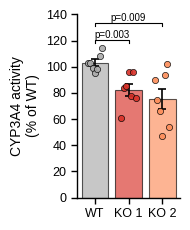

Saved: Fig3J_CYP3A4_activity_assay.pdf


In [8]:
df=pd.read_csv('Fig3J_CYP3A4_activity_assay_data.csv')
assay_label, ylab = 'CYP3A4 activity\n(% of WT)', 'CYP3A4 activity\n(% of WT)'

SPACING=0.75; WIDTH=0.6; XPAD=0.4
positions=[i*SPACING for i in range(3)]

fig,ax=plt.subplots(figsize=(2,2.4))
wt=df[df.group=='WT']['value'].values
tops=[]
for x,grp in zip(positions,ORDER):
    v=df[df.group==grp]['value'].values
    ax.bar(x,v.mean(),width=WIDTH,color=COLORS[grp],alpha=0.65,edgecolor='black',linewidth=0.8,zorder=2)
    ax.errorbar(x,v.mean(),yerr=sem(v),color='black',lw=1.2,capsize=3,capthick=1.2,ls='none',zorder=3)
    ax.scatter(x+np.linspace(-0.16,0.16,len(v)),v,color=COLORS[grp],edgecolors='black',
               linewidth=0.5,s=20,zorder=4,alpha=0.9); tops.append(v.max())
top=max(tops)
YMAX=140
headroom=YMAX-top
tick_h=headroom*0.08
y_levels=[top+headroom*0.15, top+headroom*0.65]
for (x,grp),y in zip(zip(positions[1:],['KO 1','KO 2']), y_levels):
    kv=df[df.group==grp]['value'].values
    p=welch_test(wt,kv,'log2','greater')
    sig_bracket(ax,positions[0],x,y,tick_h,fmt_p(p))
ax.set_xticks(positions); ax.set_xticklabels(ORDER,rotation=0)
ax.tick_params(axis='both', labelsize=9)
ax.set_ylabel(ylab,fontsize=AXTITLE)
ax.set_xlim(positions[0]-XPAD, positions[-1]+XPAD)
ax.set_ylim(0,YMAX)
plt.tight_layout()
fig.savefig('Fig3J_CYP3A4_activity_assay.pdf',bbox_inches='tight',pad_inches=0.28); plt.show()
print('Saved: Fig3J_CYP3A4_activity_assay.pdf')